# CsI(Tl)–SiPM 项目：下一阶段应做什么

2026-10-29，接续英文提交 `082607a` 及 [光电子统计/PID笔记](codex_0001_csi_pid_photon_statistics.ipynb)。
本轮复核已有结果，新增固定事件的平均时间分段诊断和噪声状态图；**没有重新拟合参数、运行新输运或改变正式事件选择**。

建议顺序：**run12 噪声状态 → Co 尾部与带中心 → 参数族与最终 MC 统计 → 更新论文结果**。
前三项可用现有实验数据和已有模拟框架推进，论文结果整理可同步开始。
当前可以按“已有波形的 PID 方法比较与条件响应模型检验”推进文章；实验逐事件真标签与独立器件标定仍缺失。


In [1]:
from pathlib import Path
import json, sys, hashlib
import numpy as np
from IPython.display import display, Markdown, Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'analysis/paper_baseline/results/next_steps_20261029'
def read(p):return json.loads(Path(p).read_text())
def table(headers,rows):
    return '\n'.join(['|'+'|'.join(headers)+'|','|'+'|'.join(['---']*len(headers))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
audit=read(OUT/'audit.json');evidence=read(OUT/'local_evidence.json')
latest=read(PROJECT/'simulation/results/pid_npe_20261029/validation/assessment.json')
print('Python / NumPy:',sys.version.split()[0],np.__version__)
rows=[]
for run in [3,12,18]:
    r=latest['checks'][f'run{run}_last20']
    rows.append([run,', '.join(f'{v:.3f}' for v in r['IQR_ratio']),
                 f"{r['mean_ADC_normalized_RMSE']*100:.2f}%",', '.join(f'{x:.3f}' for x in r['median_shift_in_data_IQR'])])
display(Markdown(table(['run','QDC / 平均时间 / PCA 带宽比','平均ADC NRMSE/峰','各带中心差/实验IQR'],rows)))

Python / NumPy: 3.13.5 2.5.4


|run|QDC / 平均时间 / PCA 带宽比|平均ADC NRMSE/峰|各带中心差/实验IQR|
|---|---|---|---|
|3|1.168, 0.954, 1.036|0.96%|0.236, 0.786, 0.299|
|12|0.897, 0.822, 0.858|1.17%|-0.075, 0.062, -0.003|
|18|0.948, 0.993, 1.087|0.96%|0.007, 0.102, -0.017|

## 1. 先把 run12 的采集噪声状态带入最新模型

最后20%的平均时间带宽比仍为 **0.822，固定模型95%区间约[0.662,0.994]**；这是未作多重比较校正的条件统计区间。
实测基线 RMS 从前段约3.17 ADC上升到后段5.68 ADC。下图可见变化发生在采集过程的后部，run3和run18相对稳定。

项目已经有 `refit_readout_baseline.py`、`refit_baseline_mixture.py`，此前也做过基线条件化。
下一步的新增价值是把它们接到**最新光电子统计候选**，并分开噪声估计事件与 PID 检查事件。
建议按原始序号块交叉估计：一组块只读触发前样点来拟合状态，在另一组块检查 PID，再交换。
邻近块仍可能相关，需保留块重采样和间隔/块长敏感性，不能把“ID不重合”称为完全统计独立。

保留三个预先规定的响应对照：当前固定前段噪声；仅改变噪声尺度；再加入触发前数据约束的相关谱和基线状态。
保持光学参数、光电子规模、共同电压传输和信号期残差固定，用同一批 Geant4 光子历史做成对原生重放。
同时报告固定原ID/Q箱与重新执行正式筛选的结果，以分清噪声效应和选择迁移。

验收依据是留出事件的基线 RMS/相关性、三个 PID 的中心/宽度、均波形和短尺度 F 是否共同改善；
若 RMS 对照解释不了差异，应保留该结果。触发前窗口有限，微秒尺度相关项仍可能不可辨识。
这些是以实测前触发状态为条件的比较，不能称为从前60%预测整个后段的盲验证。


上表两组计数仅说明交叉估计可行；本轮还没有进行新的噪声拟合。


|run|段|主带诊断条数|实验基线RMS|当前MC基线RMS|64事件块奇偶两组条数|
|---|---|---|---|---|---|
|3|first60|2423|3.353|3.350|1217/1206|
|3|middle20|843|3.333|3.350|407/436|
|3|last20|821|3.317|3.350|426/395|
|12|first60|1547|3.167|3.174|787/760|
|12|middle20|460|4.415|3.174|236/224|
|12|last20|407|5.677|3.174|211/196|
|18|first60|3000|4.965|4.894|1501/1499|
|18|middle20|2999|4.986|4.894|1513/1486|
|18|last20|3000|4.950|4.894|1505/1495|

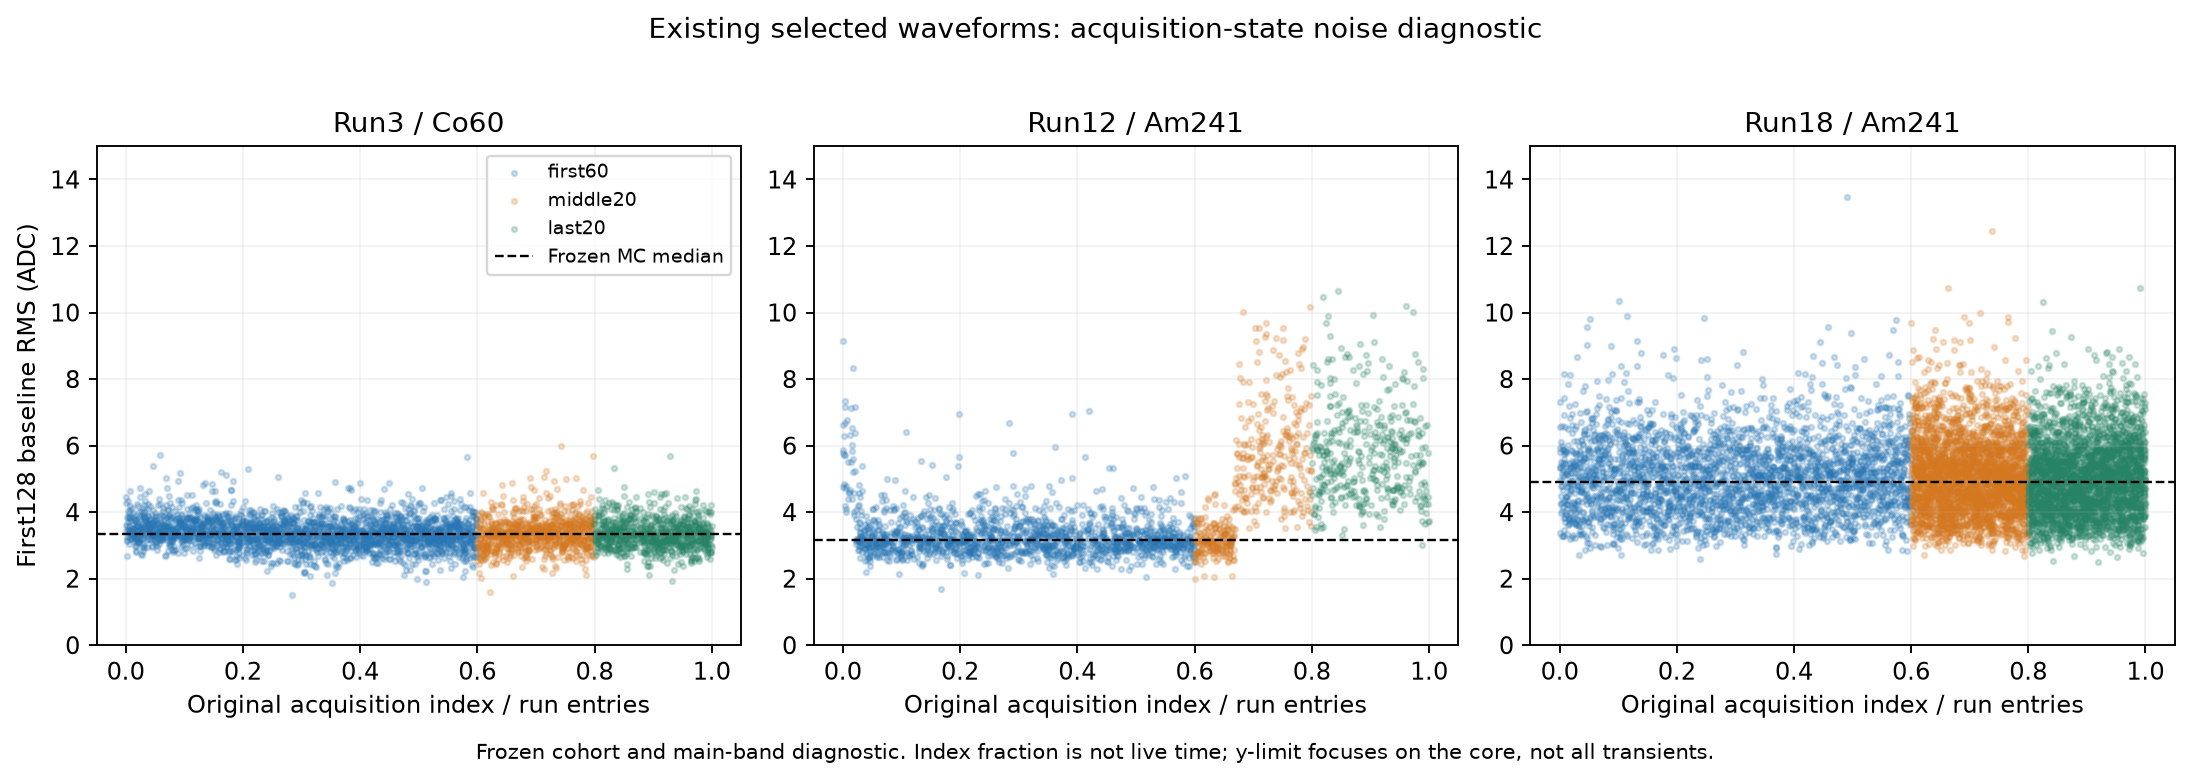

In [2]:
rows=[]
for run in [3,12,18]:
    for seg in ['first60','middle20','last20']:
        r=audit['groups'][f'run{run}_{seg}']
        rows.append([run,seg,r['n'],f"{r['data']['baseline_RMS_median']:.3f}",
          f"{audit['MC'][str(run)]['baseline_RMS_median']:.3f}",'/'.join(map(str,r['block64_parity_n']))])
display(Markdown(table(['run','段','主带诊断条数','实验基线RMS','当前MC基线RMS','64事件块奇偶两组条数'],rows)))
display(Image(filename=str(OUT/'noise_state_review.png')))
print('上表两组计数仅说明交叉估计可行；本轮还没有进行新的噪声拟合。')

## 2. Co 的中心偏移应重点检查2–3 µs尾部

本轮将正式定义下的每条波形平均时间精确拆成时间片贡献：

$$\mu=\sum_k\frac{\sum_{i\in k} t_i\,(ADC_i-\widehat B)}{Q_{\rm long}}.$$

每条波形分母保持自己的正式长门电荷，各Q箱内取均值，再对原支持箱等权。
下面是 MC 减实测的**平均时间均值差**，不是前表的中位数带中心差；两种统计量不能混用。
贡献之和按逐采样恒等式核对。负向差主要出现在2–3 µs，其他时间片部分抵消，不能把单片贡献除总差当成因果百分比。

前段和后段的总差都约为−16 ns。替代近期128点基线后仍约−15 ns；双方积分锚点统一移动±1采样点也不能消除。
这是定位检查顺序的点估计，未为分片差另算区间，不能独立证明某个具体材料或电路机制。

原平均形状拟合对0–600 ns给4倍权重；描述量包括峰时、积分比、峰值和上升时间，没有显式约束平均时间或2–3 µs尾部积分。
当前电子慢分量约700 ns，也接近旧拟合边界。下一步应在前60%训练中加入平均时间和分段尾部约束，检查目标权重和边界敏感性。
先比较现有发光时间/份额与共同读出参数的小范围变化；用两源联合约束共同响应，并保留平均ADC幅度、短尺度F和带宽要求。
若现有模型族不能同时满足这些量，再考虑增加有物理动机的响应自由度，并报告模型选择不确定性。


|Co段|原定义差/ns|近期基线差/ns|锚点−1样本差/ns|锚点+1样本差/ns|
|---|---|---|---|---|
|first60|-15.874|-15.399|-15.811|-15.935|
|middle20|-17.141|-16.354|-17.073|-17.202|
|last20|-16.206|-15.221|-16.144|-16.265|

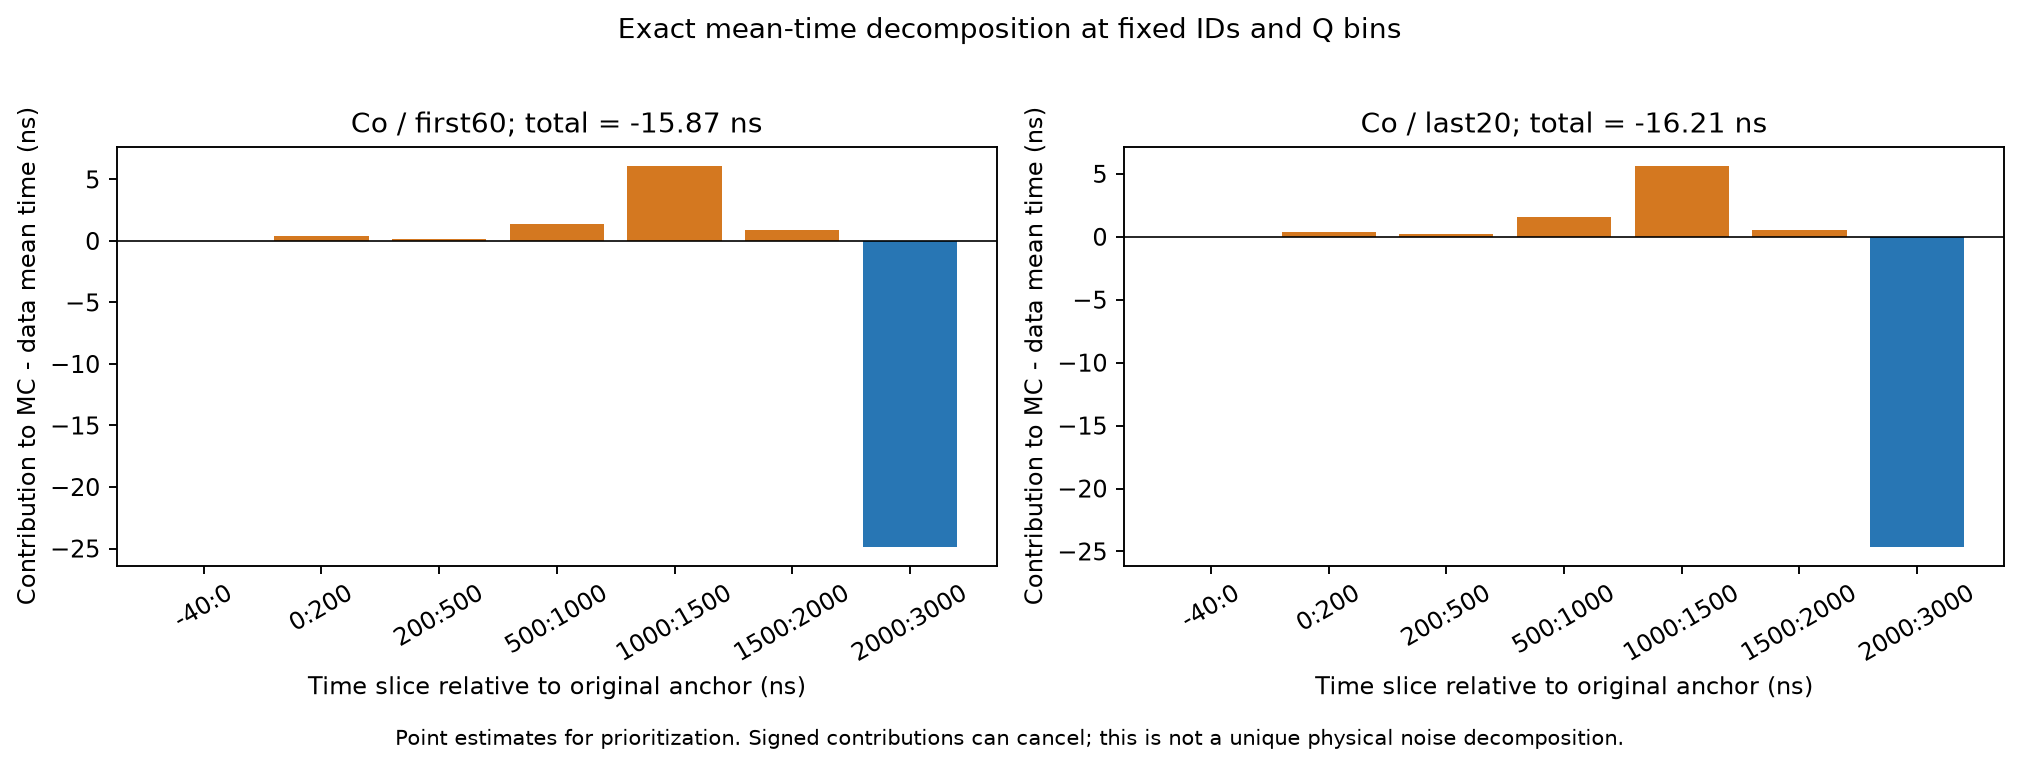

In [3]:
rows=[]
for seg in ['first60','middle20','last20']:
    r=audit['groups'][f'run3_{seg}'];v=r['MC_minus_data_variant_mean_time_ns']
    rows.append([seg,*[f'{v[k]:.3f}' for k in ['original','recent_pretrigger_baseline','anchor_shift_-1_sample','anchor_shift_+1_sample']]])
display(Markdown(table(['Co段','原定义差/ns','近期基线差/ns','锚点−1样本差/ns','锚点+1样本差/ns'],rows)))
display(Image(filename=str(OUT/'co_mean_time_review.png')))

## 3. 参数族和最终统计量应放在参数冻结后完成

目前有效光电子规模2倍与3倍的训练目标接近，单一“最佳参数”不能代表已经测得实际光产额、PDE或求和损耗。
后续至少保留这些近似可行参数族，比较它们对带中心、带宽、波形尾部、FOM及模拟阈值结果的影响。
当前的统计区间没有包含这部分模型/校准不确定性。

在状态与形状方案冻结后再追加新种子输运。可先以每类约1000个共同Q内合格事件作为提高带宽精度的规模规划，
但最终数量应由区间精度目标决定。总母衰变数、合格γ数和合格α数必须分别报告。
若要报告“模拟γ泄漏率单侧95%上限低于0.1%”，即使零误判，也需要至少2995个独立合格γ事件：
`upper = 1 - 0.05**(1/n)`。这只是固定分类器和固定选择下的二项计数上限，并不解决模型失配或实验真标签缺失。


In [4]:
s=audit['MC_statistics']
display(Markdown(table(['项目','数值'],[
 ['当前共同run12响应的模拟γ数',s['current_common_gamma']],
 ['当前0误判时的模拟泄漏单侧95%上限',f"{100*s['current_leakage_upper95']:.3f}%"],
 ['0误判且上限<0.1%所需合格γ数',s['gamma_needed_if_zero_for_upper_1e_minus3']]])))
n=s['gamma_needed_if_zero_for_upper_1e_minus3']
assert 1-.05**(1/n)<.001 and 1-.05**(1/(n-1))>=.001
print('样本量边界已核算；不能把总母事件数代入合格γ的泄漏区间。')

样本量边界已核算；不能把总母事件数代入合格γ的泄漏区间。


|项目|数值|
|---|---|
|当前共同run12响应的模拟γ数|277|
|当前0误判时的模拟泄漏单侧95%上限|1.076%|
|0误判且上限<0.1%所需合格γ数|2995|

## 4. 同步更新论文工作稿和证据层级

`analysis/paper_baseline/MANUSCRIPT_DRAFT.md` 仍以2026-10-28阶段为主体，第4.4节主要讨论旧 f=0.10 候选的短尺度差距。
最新平均波形、PID和光电子统计结果已进入 notebook/归档，但尚未系统整合进稿件。

下一版应保留冻结的实验主分析，新增模型版本表与对应数值/图，明确区分：

- **实测可支持**：同队列方法/窗口比较，采集状态和分布变化，以及所检查条件下的模型残差。
- **有条件的模拟可支持**：给定装置与参数族、沉积祖先真值和共同读出状态下的 PID 表现。
- **目前不能写成实测结果**：纯α接受率/γ泄漏率、绝对阈值/探测效率、唯一的实际PDE/光产额/电路传输。

下一阶段的完成标志应是“残差来源得到可检验的约束、模型不确定性有范围、稿件数字与冻结记录一致”。
文章不必把所有差异解释成同一种噪声；不能解释的部分应作为结果和限制保留。


## 5. 本地文献核对范围

本轮使用项目 `paper-search`，只读 `/media/sf_works/papers`。实际复用了下列既有精读笔记及项目文献表，
核对了主题/审核索引和 `global-review.md`；**没有重新阅读原PDF、联网检索或完成全球新颖性检索**。
下面页码是既有笔记记录的原文位置。交叉估计、分段均值诊断和本项目样本量规划是本项目的分析设计。


In [5]:
for p in evidence['papers']:
    text=f"**{p['authors']} ({p['year']})**，*{p['title']}*。DOI：{p['doi']}。\n\n"
    text+=f"[既有笔记](<{p['note']}>) · [原文PDF](<{p['pdf']}>)\n\n"
    text+='\n\n'.join([p['locations'],p['relevance'],p['limits'],p['adoption']])
    if 'doi_scope' in p:text+='\n\n'+p['doi_scope']
    display(Markdown(text))
display(Markdown('复现诊断：`OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 /home/xc/software/jupyter/.venv/bin/python simulation/review_next_steps.py`。结果目录拒绝覆盖，重算需另用新目录。'))
print('本轮输出：audit.json、local_evidence.json、2张图（PNG/SVG/PDF）以及本笔记。')

本轮输出：audit.json、local_evidence.json、2张图（PNG/SVG/PDF）以及本笔记。


**E. Garutti, R. Klanner, J. Rolph, J. Schwandt (2021)**，*Simulation of the response of SiPMs; Part I: Without saturation effects*。DOI：10.1016/j.nima.2021.165853。

[既有笔记](</media/sf_works/papers/sources/2021_Garutti_NIMA_Simulation-of-the-response-of-SiPMs;-Part-I-Without-saturation-effects.md>) · [原文PDF](</media/sf_works/papers/raw/2021_Garutti_NIMA_Simulation-of-the-response-of-SiPMs;-Part-I-Without-saturation-effects.pdf>)

据既有精读笔记：PDF第4页，§2.9–2.11，式(1)–(3)；第1–2页模型范围。

用分开的放电统计、单位面积单胞响应、门积分和电子学卷积组织本项目敏感性检查。

低占据模型；不独立确定本项目PDE、绝对增益或实际求和电路。不能借此把经验信号残差唯一认定为后脉冲或串扰。

笔记为AI草稿；本轮按作者名检索未发现针对本篇具体科学模型的用户采用意见，不代表完整库中所有别名均已排除。

**W. Skulski, M. Momayezi (2001)**，*Particle identification in CsI(Tl) using digital pulse shape analysis*。DOI：10.1016/S0168-9002(00)00938-4。

[既有笔记](</media/sf_works/papers/sources/2001_Skulski_NIMA_Particle-identification-in-CsI(Tl)-using-digital-pulse-shape-analysis.md>) · [原文PDF](</media/sf_works/papers/raw/2001_Skulski_NIMA_Particle-identification-in-CsI(Tl)-using-digital-pulse-shape-analysis.pdf>)

据既有精读笔记：PDF第4页基线/定时；第9–10页式(4)–(5)、图7–8的权重及带宽比较。

对当前数据固定光输出支持与方法定义，同时检查噪声相关性、时间权重、带中心和宽度。

光电二极管及电荷前放、25.6µs记录，与本项目SiPM无前放及约5µs记录不同；不移植最优滤波参数或FOM。

AI草稿；global-review.md第10560–10586行是AI归并索引，明确未新增人工确认。未发现针对本篇具体方法的明确采用答复。

复用当前项目LOCAL_EVIDENCE.md此前对Bendel2013参考文献11的核验；本轮未重新核PDF。原来源笔记首部仅给PII。

复现诊断：`OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 /home/xc/software/jupyter/.venv/bin/python simulation/review_next_steps.py`。结果目录拒绝覆盖，重算需另用新目录。